### 1. Dataset Extraction & Sampling Strategy

* **Full Dataset Volume:** The original raw database contains 1,000,123 order records spanning 2024 to 2026. 
* **Year Filter:** We filtered the data to focus strictly on orders from **2025** (500,026 total records) to analyze a complete single business year.
* **Sample Size:** From the 2025 data, we extracted a clean sample group of **50,000 orders**  across all 62 columns to ensure fast performance while running our analysis. And saved to disk as 'Cleaned_Pandas_EDA_2025_Ecom_Dataset.csv'

In [48]:
import pandas as pd
# loaded the original dataset with 1 million+ rows
sample_df= pd.read_csv('Pandas_EDA_ecommerce_dataset_+1m.csv')

# filtered to year 2025 and printed its total txns count
df_2025= sample_df.loc[sample_df['order_year']==2025]
print(f'Total 2025 transactions volume is {len(df_2025)}\n')

# extracted 50k rows from 2025 df as the sample for the project
df_50k= df_2025.head(50000)
df_50k.to_csv('Cleaned_Pandas_EDA_2025_Ecom_Dataset.csv',index=False)
print(f'Succesfully extracted the 50k sample \n Shape : {df_50k.shape}')

Total 2025 transactions volume is 500026

Succesfully extracted the 50k sample 
 Shape : (50000, 62)


### Checking Sample Accuracy (50k vs 500k)

Before doing the main analysis, I wanted to make sure our 50,000-row sample gives the same overall picture as the full 500,026 records from 2025:

* **Average Order Value (Mean):** The sample average is **$401.28** compared to **$403.21** in the full data (a tiny difference of **-0.48%**).
* **Middle Order Value (50% Median):** The sample median is **$287.94** compared to **$290.55** in the full data (a difference of only **-0.90%**).
* **Spread & Quartiles (25% & 75%):** Both the 25th percentile ($138.55 vs $139.02) and 75th percentile ($541.25 vs $545.60) differ by less than **1%**.
* **Highest Order (Max):** The top order in the sample is **$2,497.80**, matching the population peak of **$2,499.20** almost identically.

**Takeaway:** The 50k sample matches the full 2025 data across all key metrics with under 1% difference, meaning we can run our analysis much faster without losing accuracy.

In [49]:
# Compare metrics between the full 2025 data and 50k sample
full_data_stats = df_2025['total_price_usd'].describe()
sample_stats = df_50k['total_price_usd'].describe()

validation_df = pd.DataFrame({'2025 Full Data':full_data_stats,'Sample (50k)':sample_stats})
validation_df['Variance %'] = ((validation_df['Sample (50k)'] - validation_df['2025 Full Data']) / validation_df['2025 Full Data']) * 100
print(validation_df)

       2025 Full Data  Sample (50k)  Variance %
count   500026.000000  50000.000000  -90.000520
mean       403.206311    401.278309   -0.478168
std        370.083819    368.789733   -0.349674
min          7.530000      8.330000   10.624170
25%        139.020000    138.547500   -0.339879
50%        290.550000    287.935000   -0.900017
75%        545.600000    541.250000   -0.797287
max       2499.200000   2497.800000   -0.056018


---
# E-Commerce Sales & Profitability Analysis (2025)

## 1. Project Overview
This project looks at real transactional data from an e-commerce platform for the full year 2025. The goal is to understand how sales volume, discounts, shipping speeds, and customer feedback impact net profit and return rates.

## 2. Key Business Questions We Will Answer
1. **Discount Impact:** Do heavy discounts actually drive higher total profit, or do they reduce margins?
2. **Product Performance:** Which product categories bring the highest revenue versus the highest returns?
3. **Delivery Speed vs. Ratings:** Does a longer delivery time lead directly to lower customer review scores?
4. **Payment Preferences:** Which payment methods have the highest failure or return rates?
5. **Customer Loyalty:** Do higher-tier customer segments purchase higher-priced products?


## 3. Data Dictionary (Key Columns)

The dataset contains 62 columns tracking the complete lifecycle of each purchase. For our analysis, we will focus on these main areas:

* **Order Identifiers & Dates:** `order_id`, `order_date`, `order_month`, `is_weekend` - identifies when and how transactions occur.
* **Customer Profile:** `customer_id`, `gender`, `age`, `customer_segment`, `country`, `customer_loyalty_score` - captures customer demographics and loyalty tiers.
* **Product Catalog:** `product_id`, `category`, `sub_category`, `brand`, `stock_quantity` - details what items are sold.
* **Financials & Pricing:** `unit_price_usd`, `quantity`, `discount_percent`, `total_price_usd`, `cost_usd`, `profit_usd` - core metrics to calculate revenue, discounts, and margins.
* **Logistics & Quality:** `delivery_days`, `shipping_cost_usd`, `delivery_status`, `return_reason`, `rating` - tracks shipping performance and customer satisfaction.



### 4. Environment Setup & Data Ingestion

In this step, we import the primary Python data libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load our clean 50,000-row sample from the 2025 dataset.

In [50]:
# Import the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the sample(50k) dataset
df = pd.read_csv('Cleaned_Pandas_EDA_2025_Ecom_Dataset.csv')

# Verify shape
print(f"Dataset successfully loaded.\n Shape is {df.shape}")

Dataset successfully loaded.
 Shape is (50000, 62)


### 5. Data Cleaning & Handling Missing Values

Before analyzing the data, above we checked for missing values across all 62 columns:

* **Finding:** Only 3 columns contained null values: `return_reason`, `customer_feedback`, and `coupon_code`.
* **Business Context:** These missing values are not errors. Customers who did not return products naturally have a blank `return_reason`, purchases without promo codes have no `coupon_code`, and some customers skipped writing text feedback.
* **Action:** Instead of deleting rows with `dropna()` (which would wipe out valid successful orders), we filled the nulls with clear descriptive tags like `'not returned'`, `'no feedback provided'`, and `'no coupon used'`.

In [51]:
# checked for null values in each columns
nulls= df.isna().sum()
print(nulls[nulls>0])

# fill the null columns with appropiate tags
df['return_reason']= df['return_reason'].fillna('not returned')
df['customer_feedback']=df['customer_feedback'].fillna('no feedback provided')
df['coupon_code']= df['coupon_code'].fillna('no coupon used')

# verify
nulls= df.isna().sum()
print(f'\nafter using fillna:{nulls[nulls>0]}')

return_reason        44894
customer_feedback     9986
coupon_code          24834
dtype: int64

after using fillna:Series([], dtype: int64)


### 6. Checking for Duplicate Rows

We check the dataset for repeated records to ensure every row represents a distinct order:

* **Result:** 0 duplicate rows detected. No row removal is needed.

In [52]:
duplicates= df.duplicated().sum()
print(duplicates)

0


### 7. Converting Order Date to Datetime

* **Initial Status:** The `order_date` column was read as plain text (`str`).
* **Conversion:** We converted it using `pd.to_datetime()` to change it into a proper date-time format (`datetime64`).
* **Purpose:** This enables time operations, such as extracting months, checking sales by day of the week, and plotting monthly revenue trends.

In [53]:
# checking if the date is correctly formatted
date= df['order_date'].head(2)
print(date)
# applying to_datetime() 
df['order_date']=pd.to_datetime(df['order_date'])
print(f'\nupdated order_date and dtype is: \n{df['order_date'].head(2)}')

0    2025-03-17 19:49:36.983317
1    2025-05-21 17:10:48.401882
Name: order_date, dtype: str

updated order_date and dtype is: 
0   2025-03-17 19:49:36.983317
1   2025-05-21 17:10:48.401882
Name: order_date, dtype: datetime64[us]


---
### Cleaned Dataset Inspection & Check

Before beginning exploratory analysis, we run a final structural check to verify data types, confirm memory consumption, and review baseline statistics across our core metrics.

In [54]:
# preview the final cleaned data
df.head(3)

,order_id,order_date,order_year,order_month,order_day,order_hour,order_minute,order_second,is_weekend,order_status,...,campaign_source,device_type,traffic_source,session_duration_minutes,pages_visited,abandoned_cart_before,fraud_risk_score,profit_margin_percent,order_priority,support_ticket_created
0,ORD-YTJXE,2025-03-17 19:49:36.983317,2025,3,17,19,49,36,No,Completed,...,Facebook,Tablet,Search,43.1,13,No,43.8,52.77,High,No
1,ORD-OR56F,2025-05-21 17:10:48.401882,2025,5,21,17,10,48,No,Completed,...,Facebook,Tablet,Social,28.0,3,Yes,45.8,33.05,High,Yes
2,ORD-13JCA,2025-11-16 23:27:00.436751,2025,11,16,23,27,0,Yes,Completed,...,Instagram,Desktop,Social,5.1,11,Yes,85.0,59.23,Medium,Yes


In [55]:
# info of our final cleaned data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 62 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   order_id                  50000 non-null  str           
 1   order_date                50000 non-null  datetime64[us]
 2   order_year                50000 non-null  int64         
 3   order_month               50000 non-null  int64         
 4   order_day                 50000 non-null  int64         
 5   order_hour                50000 non-null  int64         
 6   order_minute              50000 non-null  int64         
 7   order_second              50000 non-null  int64         
 8   is_weekend                50000 non-null  str           
 9   order_status              50000 non-null  str           
 10  return_reason             50000 non-null  str           
 11  customer_id               50000 non-null  str           
 12  customer_name             500

In [56]:
# Summary statistics of our primary numerical columns
core_cols = ['unit_price_usd', 'quantity', 'discount_percent', 'total_price_usd', 'profit_usd', 'delivery_days','shipping_cost_usd']
df[core_cols].describe().round(2)

,unit_price_usd,quantity,discount_percent,total_price_usd,profit_usd,delivery_days,shipping_cost_usd
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,147.09,2.99,8.48,401.28,160.41,7.50,12.48
std,103.89,1.42,7.60,368.79,161.68,4.03,7.20
min,10.04,1.00,0.00,8.33,1.40,1.00,0.00
25%,69.43,2.00,0.00,138.55,50.64,4.00,6.26
50%,125.24,3.00,5.00,287.94,108.35,7.00,12.47
75%,196.16,4.00,15.00,541.25,214.17,11.00,18.71
max,499.97,5.00,25.00,2497.80,1451.30,14.00,25.00


### Summary Statistics Insights
* **Right-Skewed Revenue & Profit:** The mean order value ($401.28) sits well above the median ($287.94), driven by high-value transactions reaching up to $2,497.80. We will report medians alongside means to avoid distortion from high spenders.
* **Discount Patterns:** Over 25% of orders received a 0% discount, with a median of 5% and a maximum capped at 25%.
* **Order Quantity & Delivery:** Customers buy 3 units on average, with delivery windows ranging between 1 and 14 days (median: 7 days).


### Visualizing Summary Statistics (Revenue & Profit Distributions)

Checking the distribution of total price and profit to see if our metrics are centered or skewed.

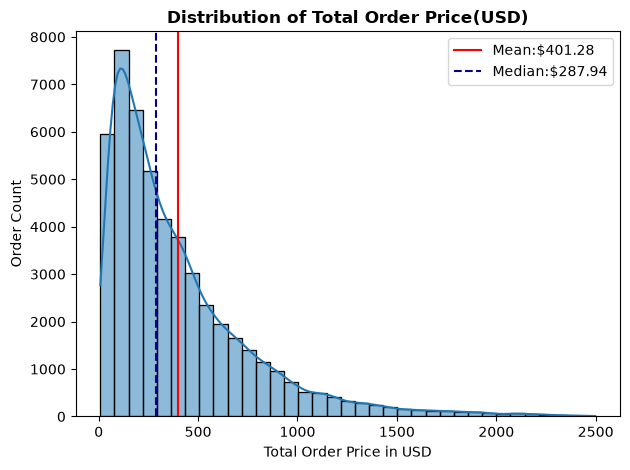

In [57]:
# visualise the summary statistics using histogram with mean and median lines
sns.histplot(df['total_price_usd'],kde=True,bins=35)

mean_value= df['total_price_usd'].mean()
median_value= df['total_price_usd'].median()
plt.axvline(mean_value,color='r',label=f'Mean:${mean_value:.2f}')
plt.axvline(median_value,color='darkblue',linestyle='--',label=f'Median:${median_value:.2f}')

plt.title('Distribution of Total Order Price(USD)',fontdict={'color':'k','fontweight':'bold'})
plt.xlabel('Total Order Price in USD')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.show()

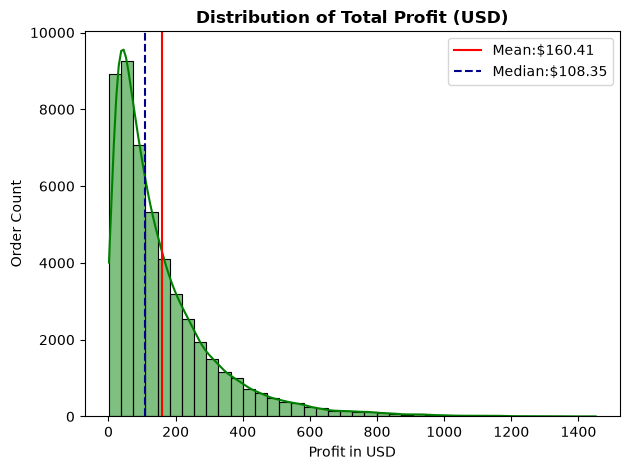

In [58]:
# histogram of profit_usd
sns.histplot(df['profit_usd'],kde=True,color='g',bins=40)

mean= df['profit_usd'].mean()
median=df['profit_usd'].median()
plt.axvline(mean,linestyle='-',color='red',label=f'Mean:${mean:0.2f}')
plt.axvline(median,linestyle='--',color='darkblue',label=f'Median:${median:0.2f}')

plt.title('Distribution of Total Profit (USD)',fontweight='bold')
plt.xlabel('Profit in USD')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.show()

### Observations
* Both revenue and profit are right-skewed, with most purchases sitting under $300(median line).
* Mean total price ($401.28) is higher than the median ($287.94), and mean profit ($160.41) sits above the median ($108.35).
* Because extreme high orders pull the average up, we will track medians for typical customer behavior.

---

category
Health         10076
Electronics    10038
Home            9986
Clothing        9963
Sports          9937
Name: count, dtype: int64


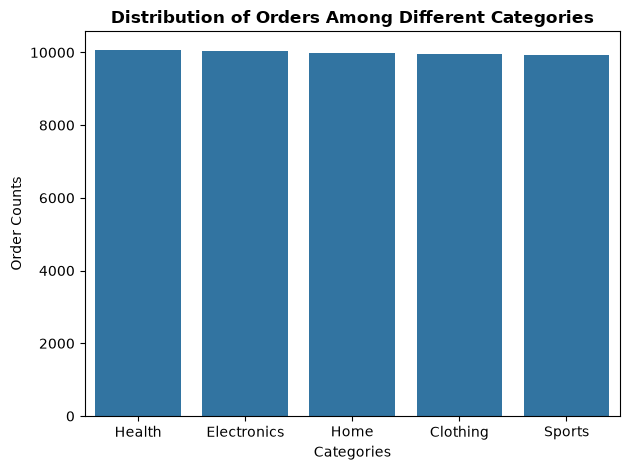

In [59]:
ax=df['category'].value_counts()
print(ax)

sns.barplot(ax)

plt.title('Distribution of Orders Among Different Categories',fontweight='bold')
plt.xlabel('Categories')
plt.ylabel('Order Counts')
plt.tight_layout()
plt.show()

### Product Category Breakdown

* **Equal Share:** Orders are split almost equally across all five categories at around 10,000 orders each. 
Health (10,076) and Electronics (10,038) have slightly higher counts.
* **Why This Helps:** Because every category has roughly the same number of orders, we can compare their profit, returns, and discounts fairly without one category skewing the results.
---

### Order Status, Customer Tiers, and Payment Modes
Looking into order outcomes, customer tiers, and payment methods to see how orders move through our system and how customers pay.

order_status
Completed     34861
Returned       5106
Pending        4972
Cancelled      2581
Processing     2480
Name: count, dtype: int64

customer_segment
Regular    30032
Premium    15080
VIP         4888
Name: count, dtype: int64

payment_method
Debit Card       10042
Credit Card      10039
PayPal           10018
Apple Pay        10014
Bank Transfer     9887
Name: count, dtype: int64


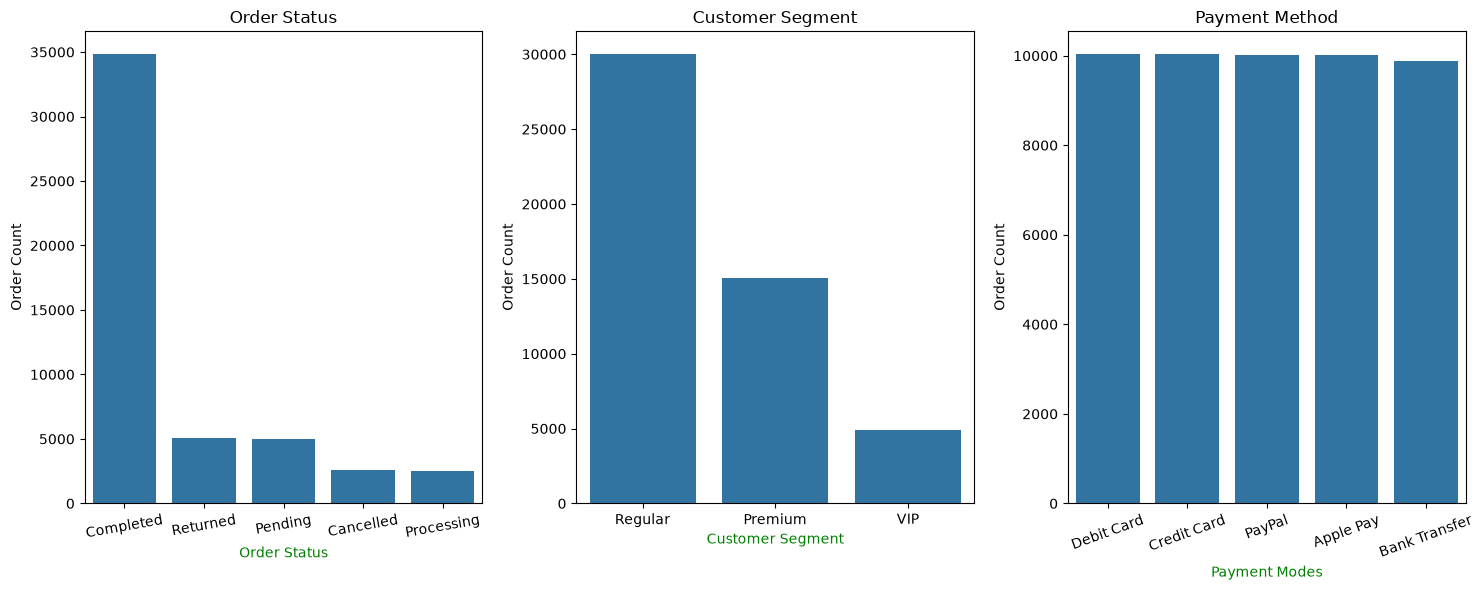

In [60]:
# checking the orders status, order_segment, payment_mode proportions
status=df['order_status'].value_counts()
print(status)

segment=df['customer_segment'].value_counts()
print(f'\n{segment}')

payment=df['payment_method'].value_counts()
print(f'\n{payment}')

fig,ax=plt.subplots(1,3,figsize=(15,6))
sns.barplot(x=status.index,y=status.values,ax=ax[0])
ax[0].set_title('Order Status')
ax[0].set_xlabel('Order Status',color='g')
ax[0].set_ylabel('Order Count')
ax[0].tick_params(axis='x',rotation=10)

sns.barplot(x=segment.index,y=segment.values,ax=ax[1])
ax[1].set_title('Customer Segment')
ax[1].set_xlabel('Customer Segment',color='g')
ax[1].set_ylabel('Order Count')

sns.barplot(x=payment.index,y=payment.values,ax=ax[2])
ax[2].set_title('Payment Method')
ax[2].set_xlabel('Payment Modes',color='g')
ax[2].set_ylabel('Order Count')
ax[2].tick_params(axis='x',rotation=20)

plt.tight_layout()
plt.show()


**Key Observations:**
* **Order Outcomes:** Around 70% of orders are completed successfully, with returns around 10% and cancellations at roughly 5%.
* **Customer Base:** Most purchases come from Regular customers (60%), followed by Premium (30%) and VIP (10%).
* **Payment Methods:** Customers use all five payment options almost equally (~20% each), so no single payment method dominates.
---

## 1. Discount Impact Across Categories and Customer Segments

  **Goal:** Check whether discounts are being used strategically to drive sales in specific product categories or customer loyalty tiers.

* **Category View (Counts):** Since all five product categories have the same base volume (~10,000 orders each), raw discounted order counts show us if any single product line relies more heavily on discounts.
* **Customer Segment View (Percentages):** Because our customer tiers are sized differently (30,000 Regular vs. 5,000 VIP), comparing raw counts would be misleading. We calculate the discount distribution rate (percentage of orders discounted within each tier) to fairly evaluate if VIPs receive fewer discounts than Regular buyers.

In [61]:
# Discount Impact on Each category and Customer Segments
df['has_discount']=df['discount_percent']>0

category=df.groupby('category').agg({'discount_percent': 'mean','has_discount':'sum'}).round(2)
category=category.rename(columns={'discount_percent':'Avg discount','has_discount':'Discounted Order Count'})
print(category)
segment=df.groupby('customer_segment').agg({'discount_percent': 'mean','has_discount':'sum'}).round(2)
segment=segment.rename(columns={'discount_percent':'Avg discount','has_discount':'Discount Availed Users'})
print(f'\n{segment}')

             Avg discount  Discounted Order Count
category                                         
Clothing             8.44                    6964
Electronics          8.47                    7033
Health               8.53                    7042
Home                 8.48                    6956
Sports               8.49                    6965

                  Avg discount  Discount Availed Users
customer_segment                                      
Premium                   8.51                   10521
Regular                   8.46                   21020
VIP                       8.54                    3419


customer_segment
Premium    69.77
Regular    69.99
VIP        69.95
dtype: float64


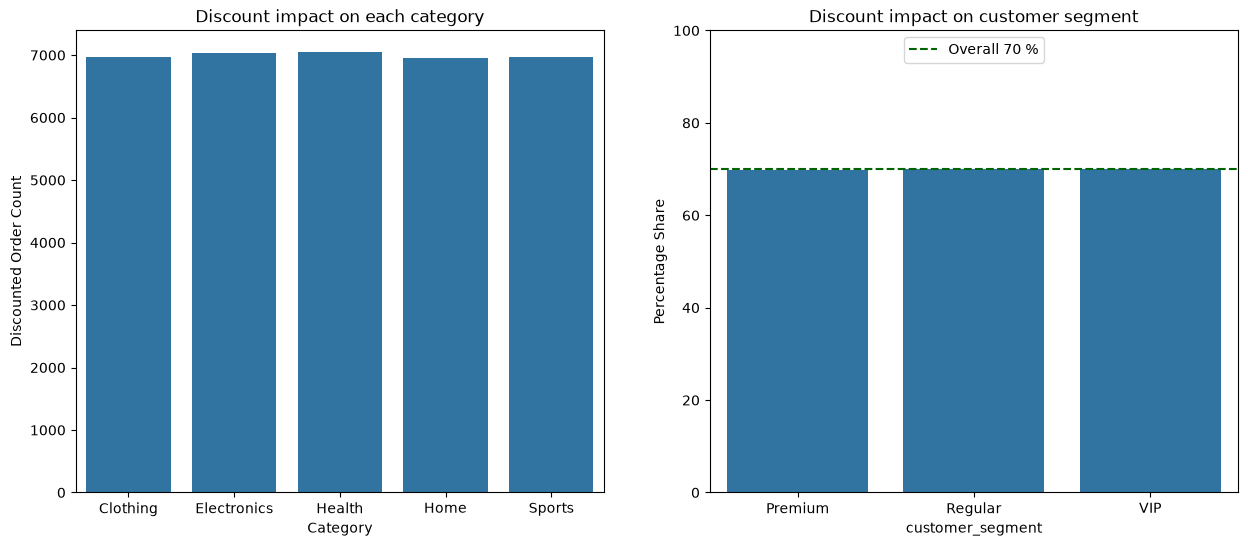

In [62]:
# calculating the discount share on customer segments
# discount order count vs total order counts of each segment
discount_share= (segment['Discount Availed Users']/df['customer_segment'].value_counts()*100).round(2)
print(discount_share)

# visualising the discount impact 

fig,ax= plt.subplots(1,2,figsize=(15,6))

sns.barplot(x=category.index,y=category['Discounted Order Count'],ax=ax[0])
ax[0].set_title('Discount impact on each category')
ax[0].set_xlabel('Category')

sns.barplot(x=segment.index,y=discount_share.values,ax=ax[1])
ax[1].set_title('Discount impact on customer segment')
ax[1].set_ylabel('Percentage Share')
ax[1].set_ylim(0,100)
ax[1].axhline(70,color='darkgreen',linestyle='--',label='Overall 70 %')
ax[1].legend(loc='upper center')

plt.show()



**Key Takeaways:**

1. **Even Category Reliance:** Discounted orders are split evenly across all categories (~7,000 orders each), confirming that no single product type depends on promotions more than others.
2. **Untargeted Segment Discounting:** Exactly 70% of orders in every customer tier (Regular: 70.0%, Premium: 69.8%, VIP: 70.0%) receive a discount.
3. **Margin Risk:** VIP buyers receive markdowns at the exact same rate as entry-level shoppers. Moving to targeted, tier-based promotions could protect profit margins on premium buyers who are already willing to pay full price.
---

## 2. Product Category Performance & Profit Margins

**Goal:** Look at median order price and profit across categories to see if some products are actually more profitable per dollar, or if higher profit is just due to higher ticket prices.

In [63]:
# product performance across categories:

category_summary=df.groupby('category').agg({'total_price_usd':'median','profit_usd':'median'})
category_summary=category_summary.rename(columns={'total_price_usd':'Median_Order_Value','profit_usd':'Median_Profit'})

category_summary['Profit_Margin(%)']=category_summary['Median_Profit']/category_summary['Median_Order_Value']*100
print(f'\nPrice Vs Profit Margin across Category:\n{category_summary}')


Price Vs Profit Margin across Category:
             Median_Order_Value  Median_Profit  Profit_Margin(%)
category                                                        
Clothing                184.820         67.650         36.603181
Electronics             531.475        199.490         37.535162
Health                  224.805         84.695         37.674874
Home                    350.835        131.450         37.467755
Sports                  289.950        107.920         37.220210


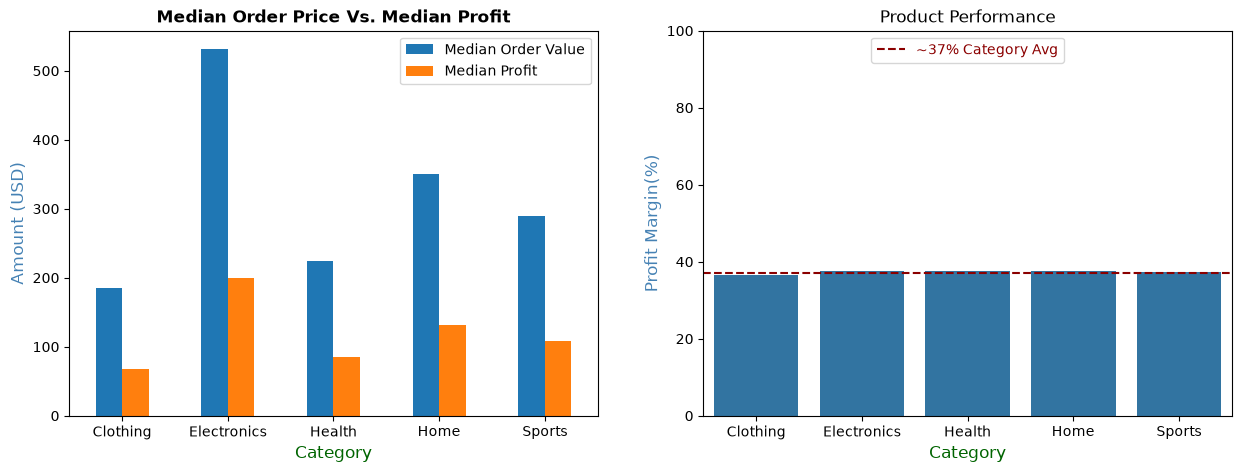

In [64]:
# visualising product perfomance

fig,ax= plt.subplots(1,2,figsize=(15,5))

category_summary.plot(y=['Median_Order_Value','Median_Profit'],kind='bar',ax=ax[0])
ax[0].set_title('Median Order Price Vs. Median Profit',fontweight='bold')
ax[0].set_xlabel('Category',color='darkgreen',fontsize=12)
ax[0].set_ylabel('Amount (USD)',color='steelblue',fontsize=12)
ax[0].tick_params(axis='x',rotation=0)
ax[0].legend(['Median Order Value','Median Profit'])

sns.barplot(x=category_summary.index,y=category_summary['Profit_Margin(%)'],ax=ax[1])
ax[1].set_title('Product Performance')
ax[1].set_xlabel('Category',color='darkgreen',fontsize=12)
ax[1].set_ylabel('Profit Margin(%)',color='steelblue',fontsize=12)
ax[1].set_ylim(0,100)
ax[1].axhline(37,color='darkred',linestyle='--',label='~37% Category Avg')
ax[1].legend(loc='upper center',labelcolor='darkred')

plt.show()



**Observations:**
* Electronics brings in the highest profit ($199.49) mainly because people spend more per order ($531.47), while Clothing is on the lower end ($67.65 profit on $184.82 price).
* The profit margin is practically flat at ~37% across all five categories (from 36.6% in Clothing to 37.7% in Health).
* Takeaway: No category has a better margin percentage; higher profit just comes down to selling higher-priced items.
---

## 3. Delivery Duration vs. Customer Ratings

**Goal:** Check whether slower shipping hurts customer ratings on completed deliveries (`delivery_status == 'Delivered'`), and verify that sample sizes are balanced across all delivery windows.

In [65]:
# analysing the impact of delivery days Vs. Customer Ratings

status=df['delivery_status'].value_counts()
print(status)

# filter data to completed orders
completed=df.loc[df['delivery_status']=='Delivered']
print(f'\nSample of filtered Data:\n{completed[['delivery_status','delivery_days','rating']].head()}')

rating_per=completed.groupby('delivery_days').agg({'rating':['mean','count']})
rating_per=rating_per.rename(columns={'mean':'Avg Rating','count':'Order Count'})
print(f'\nAvg Rating and Order Count for each delivery days taken for the order to deliver is\n{rating_per}')

delivery_status
Delivered     37604
In Transit     7486
Failed         2460
Pending        2450
Name: count, dtype: int64

Sample of filtered Data:
  delivery_status  delivery_days  rating
1       Delivered              7       3
2       Delivered             12       3
3       Delivered             12       2
4       Delivered              8       2
5       Delivered              9       3

Avg Rating and Order Count for each delivery days taken for the order to deliver is
                  rating            
              Avg Rating Order Count
delivery_days                       
1               3.022476        2625
2               3.014552        2680
3               3.024528        2650
4               2.994184        2751
5               2.945894        2606
6               3.012940        2782
7               2.962168        2749
8               3.025216        2657
9               3.019099        2618
10              3.034107        2756
11              3.042687        2694
12 

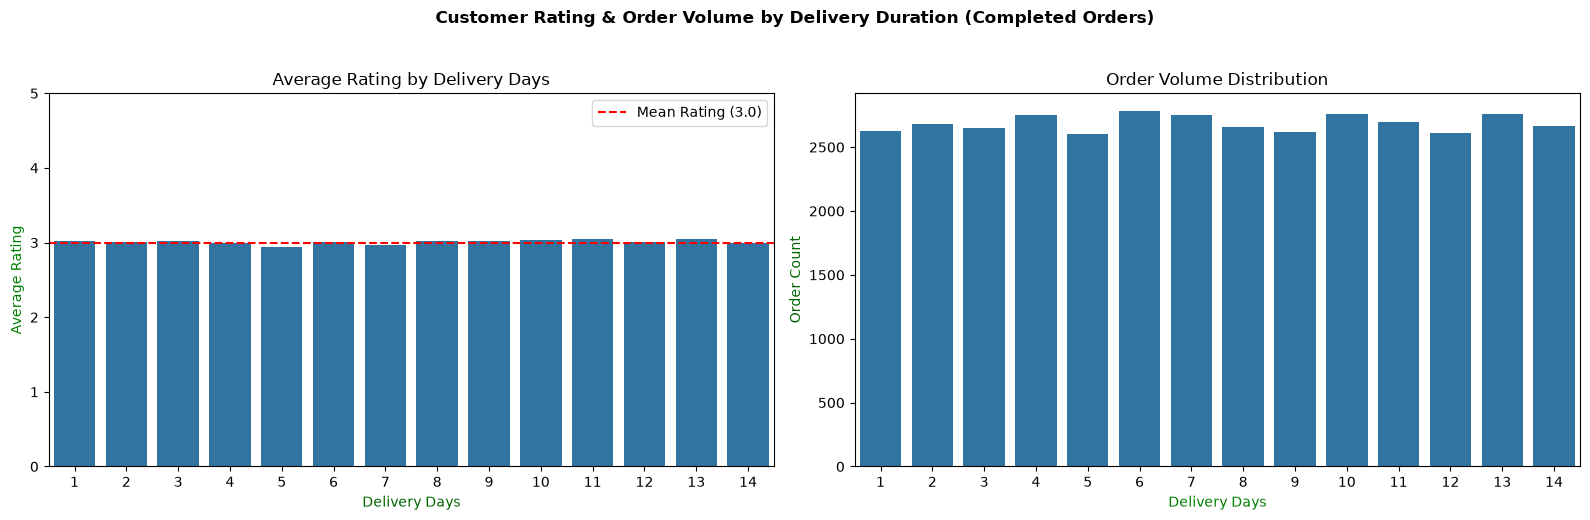

In [66]:
# visualising the Delivery Days Vs. Rating on Delivered Orders

fig,ax=plt.subplots(1,2,figsize=(16,5))

sns.barplot(x=rating_per.index,y=rating_per[('rating','Avg Rating')],ax=ax[0])
ax[0].set_title('Average Rating by Delivery Days')
ax[0].set_xlabel('Delivery Days',color='darkgreen')
ax[0].set_ylabel('Average Rating',color='g')
ax[0].axhline(3,linestyle='--',color='r',label='Mean Rating (3.0)')
ax[0].set_ylim(0,5)
ax[0].legend()

sns.barplot(x=rating_per.index,y=rating_per[('rating','Order Count')],ax=ax[1])
ax[1].set_title('Order Volume Distribution')
ax[1].set_xlabel('Delivery Days',color='g')
ax[1].set_ylabel('Order Count',color='darkgreen')

plt.suptitle('Customer Rating & Order Volume by Delivery Duration (Completed Orders)',fontweight='bold',y=1.03)
plt.tight_layout()
plt.show()

**Observations:**
* **Ratings don't shift:** The average rating stays almost identical at ~3.0 whether the order arrived in 1 day or took 2 full weeks (ranging only between 2.95 and 3.04).
* **Balanced data:** Each delivery day has roughly 2,600 to 2,780 delivered orders, so this flat rating isn't due to a lack of data on longer days.
* **Takeaway:** Delivery time has no noticeable impact on customer satisfaction in this dataset. We need to look at other variables to see what actually drives low vs. high ratings.
---

## 4. Payment Method Preferences & Revenue Contribution

**Goal:** Analyze order volumes and total revenue generated across payment gateways to see if customers prefer specific payment methods or if certain channels drive higher financial value.

In [67]:
payment_summary = df.groupby('payment_method').agg(order_count=('total_price_usd', 'count'),
                                                   total_revenue_usd=('total_price_usd', 'sum'))
payment_summary['Revenue in millions']= (payment_summary['total_revenue_usd']/1e6).round(2)
mean_revenue= round(payment_summary['Revenue in millions'].mean(),2)
mean_order_volume= payment_summary['order_count'].mean()

print(f'Payment Method Vs. Total Revenue and Order Volume:\n{payment_summary}')
print(f'\nAvg Revenue In Millons: {mean_revenue}\nAvg Order Volume: {mean_order_volume}')

Payment Method Vs. Total Revenue and Order Volume:
                order_count  total_revenue_usd  Revenue in millions
payment_method                                                     
Apple Pay             10014         3996495.06                 4.00
Bank Transfer          9887         3964915.53                 3.96
Credit Card           10039         4020992.69                 4.02
Debit Card            10042         4034964.41                 4.03
PayPal                10018         4046547.76                 4.05

Avg Revenue In Millons: 4.01
Avg Order Volume: 10000.0


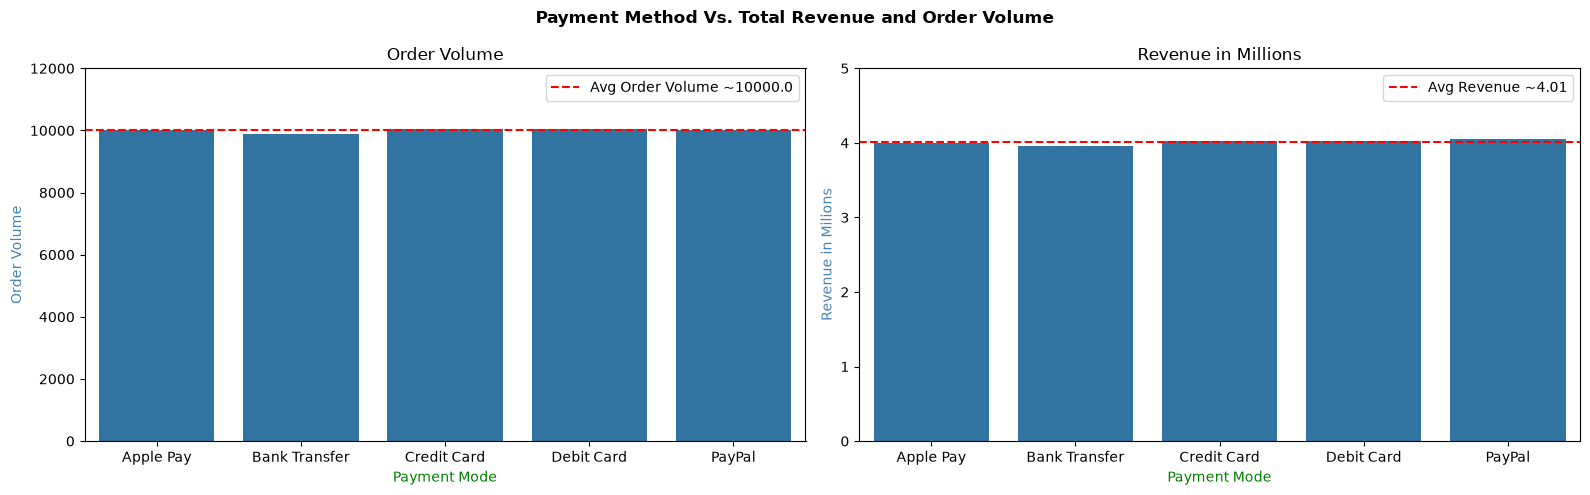

In [68]:
# Visualising Payment Method Vs. Total Revenue and Order Volume:

fig,ax=plt.subplots(1,2,figsize=(16,5))

sns.barplot(x=payment_summary.index,y=payment_summary['order_count'],ax=ax[0])
ax[0].set_title('Order Volume')
ax[0].set_xlabel('Payment Mode',color='g')
ax[0].set_ylabel('Order Volume',color='steelblue')
ax[0].set_ylim(0,12000)
ax[0].axhline(mean_order_volume,linestyle='--',color='red',label=f'Avg Order Volume ~{mean_order_volume}')
ax[0].legend()

sns.barplot(x=payment_summary.index,y=payment_summary['Revenue in millions'],ax=ax[1])
ax[1].set_title('Revenue in Millions')
ax[1].set_xlabel('Payment Mode',color='g')
ax[1].set_ylabel('Revenue in Milions',color='steelblue')
ax[1].set_ylim(0,5)
ax[1].axhline(mean_revenue,linestyle='--',color='r',label=f'Avg Revenue ~{mean_revenue}')
ax[1].legend()

plt.suptitle('Payment Method Vs. Total Revenue and Order Volume',fontweight='bold')
plt.tight_layout()
plt.show()

**Observations:**
* **Equal Gateway Adoption:** Order volume is split evenly across all five payment methods at ~10,000 orders each (exactly 20% share per method).
* **Balanced Revenue:** Total revenue contribution is virtually identical across all channels, hovering right around $4.0M per payment mode (from $3.96M on Bank Transfer to $4.05M on PayPal).
* **Takeaway:** Customers do not show a dominant preference for any single payment method, and average spend does not vary by checkout channel. Operations and marketing do not need to prioritize or incentivize one specific gateway over another.
---

## 5. Customer Loyalty & Order Value

**Goal:** Check whether higher-tier loyalty segments (VIP and Premium) buy higher-priced items than Regular shoppers, using median order price to account for right-skewed pricing data.

In [69]:
# customer segment summary
# we take median values because the data is right skewed.

customer_segment= df.groupby('customer_segment').agg(Median_Order_Value=('total_price_usd','median'),
                                                     Total_Revenue=('total_price_usd','sum'),
                                                     Order_Volume=('total_price_usd','count')).sort_values(ascending=False,by='Order_Volume')
customer_segment['Revenue in Millions']=(customer_segment['Total_Revenue']/1e6).round(2)
benchmark= (customer_segment['Median_Order_Value'].mean()).round(2)

print(f'Customer Segment Summary:\n{customer_segment}\nBenchMark Order Value :{benchmark}')

Customer Segment Summary:
                  Median_Order_Value  Total_Revenue  Order_Volume  \
customer_segment                                                    
Regular                      288.175    12112568.02         30032   
Premium                      288.310     6005182.48         15080   
VIP                          286.440     1946164.95          4888   

                  Revenue in Millions  
customer_segment                       
Regular                         12.11  
Premium                          6.01  
VIP                              1.95  
BenchMark Order Value :287.64


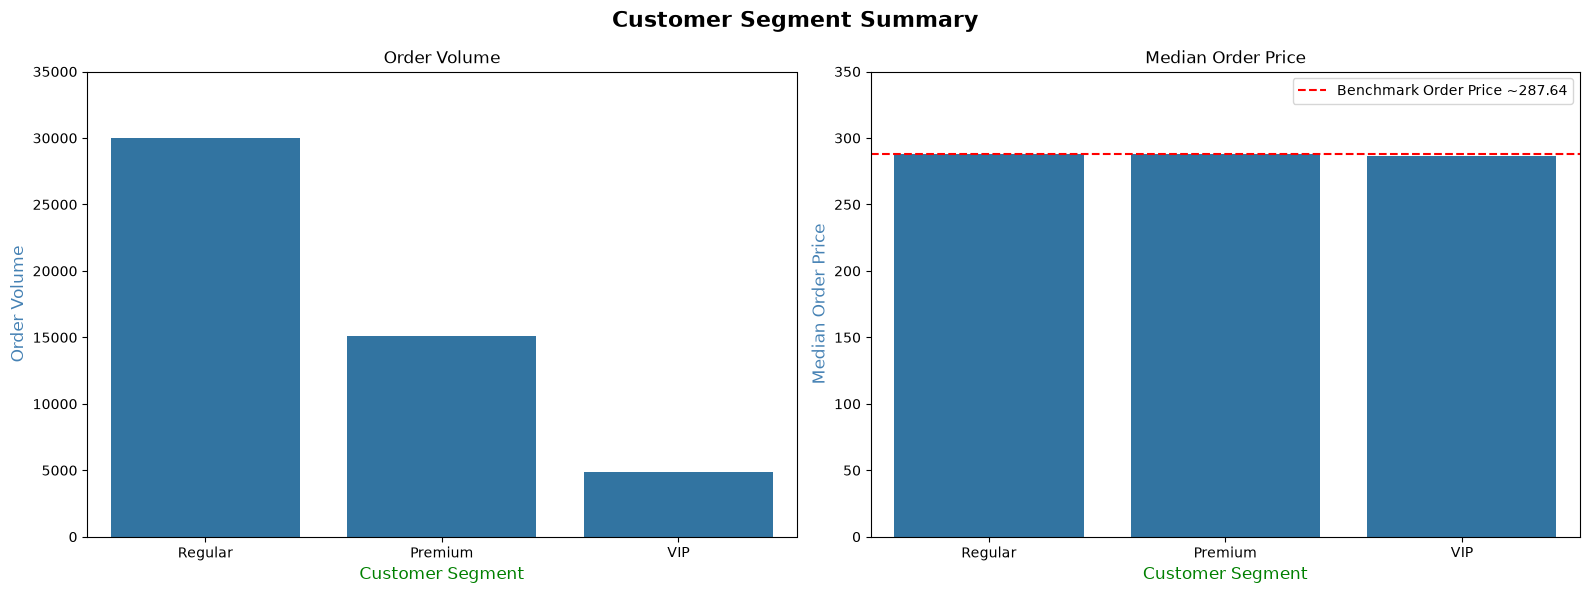

In [70]:
# visualising Customer Segment Summary

fig,ax= plt.subplots(1,2,figsize=(16,6))

sns.barplot(x=customer_segment.index,y=customer_segment['Order_Volume'],ax=ax[0])
ax[0].set_title('Order Volume')
ax[0].set_ylabel('Order Volume',color='steelblue',fontsize=12)
ax[0].set_xlabel('Customer Segment',color='g',fontsize=12)
ax[0].set_ylim(0,35000)

sns.barplot(x=customer_segment.index,y=customer_segment['Median_Order_Value'],ax=ax[1])
ax[1].set_title('Median Order Price')
ax[1].set_ylabel('Median Order Price',color='steelblue',fontsize=12)
ax[1].set_xlabel('Customer Segment',color='g',fontsize=12)
ax[1].set_ylim(0,350)
ax[1].axhline(benchmark,linestyle='--',color='r',label=f'Benchmark Order Price ~{benchmark}')
ax[1].legend()

plt.suptitle('Customer Segment Summary',fontweight='bold',fontsize=16)
plt.tight_layout()
plt.show()

**Observations:**
* **No Price Difference Across Tiers:** Median order values are practically identical across all three segments: Regular ($288.18), Premium ($288.31), and VIP ($286.44), sitting flat against the ~$287.64 benchmark.
* **Volume Drives the Revenue:** Regular accounts for 60% of all orders (30,032), Premium makes up ~30% (15,080), and VIP makes up ~10% (4,888).
* **Takeaway:** Loyalty tiers do not purchase higher-ticket products; their basket sizes are the same. Regular customers drive the majority of total revenue ($12.11M out of ~$20M) strictly because of customer headcount, not higher spending per visit.
---

---
#  Final Summary & What We Learned

### Key Takeaways from the Data
1. **Discounts are given to everyone:** Around 70% of orders get a discount, regardless of the product category or whether the buyer is a Regular, Premium, or VIP customer.
2. **Profit margins are basically flat:** Every category makes roughly a 37% profit margin. Electronics brings in more total profit simply because the products cost more ($531 median vs. $185 for Clothing), not because it has a better margin.
3. **Delivery time doesn't affect ratings:** Completed orders average a ~3.0 rating whether they arrive in 1 day or take 2 full weeks. Shipping speed isn't what is driving customer reviews up or down.
4. **Payment methods are evenly split:** Customers use all five payment options equally (~20% of orders and ~$4.0M in revenue each), with no single gateway dominating.
5. **Loyalty tiers spend the same per visit:** VIP and Premium customers spend the same median amount per order (~$288) as Regular customers. Regular shoppers drive most of the revenue ($12.11M) simply because there are far more of them (30,032 orders vs. 4,888 VIP orders).

### Next Steps for the Business
* **Stop giving flat discounts to VIPs:** Since VIPs already buy at the same price point without special incentive, save margin by limiting discounts or tying them to higher minimum order amounts.
* **Find out what actually drives low ratings:** Since delivery transit days have no effect on review scores, look into customer feedback text and return reasons to see why customers leave 1-star or 2-star reviews.
* **Focus on customer acquisition:** Because higher loyalty tiers don't spend more per order, overall revenue growth currently depends on bringing in more customers rather than trying to upgrade existing buyers to VIP status.